# Logistic Regression: is a tumor malignant or benign?

**Goal.** Predict a probability for a two-class problem.

**The model.** A linear score is squeezed into the range 0 to 1 by the sigmoid function:

$$P(y=1\mid x) = \frac{1}{1 + e^{-(w^T x + b)}}$$

The weights are learned by minimizing the **cross-entropy** loss.

**The dataset.** *Breast Cancer Wisconsin (Diagnostic)*, UCI: 569 samples and 30 numeric measurements of cell nuclei.
Target: malignant (1) or benign (0).

In [1]:
# SETUP: install any package this notebook needs but your Python does not have.
# It uses the same Python that runs this notebook, so it also works on Windows
# inside a virtual environment or Anaconda.
import importlib.util
import subprocess
import sys

required = {  # import name -> pip package name
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "sklearn": "scikit-learn",
    "certifi": "certifi"
}
missing = [pip for module, pip in required.items() if importlib.util.find_spec(module) is None]
if missing:
    print("Installing:", missing)
    subprocess.check_call([sys.executable, "-m", "pip", "install", *missing])
else:
    print("All required packages are already installed.")

All required packages are already installed.


In [2]:
# A consistent look for every figure, and a fixed random seed so that
# running the notebook twice gives the same numbers.
import warnings
import matplotlib.pyplot as plt
import numpy as np

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

PURPLE, BLUE, GREEN, ORANGE, RED = "#5A28C8", "#476ADD", "#00A651", "#F28C28", "#E0344B"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 12, "axes.titleweight": "bold", "axes.titlecolor": PURPLE,
    "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False,
})

## 1. Get the data

In [3]:
# DOWNLOAD THE DATASET
# Files are stored next to this notebook in a "data" folder, and are only
# downloaded the first time. pathlib builds correct paths on Windows.
#
# Why certifi? Some Windows machines have an out-of-date certificate store and
# fail with CERTIFICATE_VERIFY_FAILED. certifi ships an up-to-date list of trusted
# authorities, so the secure connection is still fully verified.
import shutil
import ssl
import urllib.request
import zipfile
from pathlib import Path

import certifi

def download(url, destination):
    """Download url to destination unless the file already exists."""
    destination = Path(destination)
    if destination.exists():
        print("Already downloaded:", destination)
        return destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    print("Downloading:", url)
    context = ssl.create_default_context(cafile=certifi.where())
    request = urllib.request.Request(url, headers={"User-Agent": "python"})
    temporary = destination.with_suffix(destination.suffix + ".part")
    with urllib.request.urlopen(request, context=context, timeout=600) as response, open(temporary, "wb") as output:
        shutil.copyfileobj(response, output)
    temporary.replace(destination)  # only a complete file gets the final name
    print("Saved:", destination, f"({destination.stat().st_size / 1e6:.1f} MB)")
    return destination

DATA_DIR = Path("data") / "wdbc"
archive = download("https://archive.ics.uci.edu/static/public/17/breast+cancer+wisconsin+diagnostic.zip", DATA_DIR / "dataset.zip")
with zipfile.ZipFile(archive) as z:
    z.extractall(DATA_DIR)
print("Files:", [p.name for p in DATA_DIR.rglob("*") if p.is_file()][:10])

Downloading: https://archive.ics.uci.edu/static/public/17/breast+cancer+wisconsin+diagnostic.zip


Saved: data\wdbc\dataset.zip (0.1 MB)
Files: ['dataset.zip', 'wdbc.data', 'wdbc.names']


In [4]:
import pandas as pd

# The raw file has no header: column 0 is an id, column 1 the diagnosis, the rest are features.
base = ["radius", "texture", "perimeter", "area", "smoothness", "compactness",
        "concavity", "concave_points", "symmetry", "fractal_dim"]
feature_names = [f"{name}_{kind}" for kind in ("mean", "se", "worst") for name in base]
df = pd.read_csv(DATA_DIR / "wdbc.data", header=None, names=["id", "diagnosis", *feature_names])

X = df[feature_names]
y = (df["diagnosis"] == "M").astype(int)   # 1 = malignant
print("Shape:", X.shape, "| Malignant share:", round(y.mean(), 3))

Shape: (569, 30) | Malignant share: 0.373


## 2. Split the data
`stratify=y` keeps the same share of malignant cases in the train and test sets.

In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)

## 3. Train
Scaling matters here: `area` is in the thousands and `smoothness` is around 0.1.

In [6]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]   # probability of being malignant

## 4. Evaluate
In a medical test, a missed cancer (false negative) is the worst error, so **recall** deserves special attention.

In [7]:
from sklearn.metrics import (accuracy_score, confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)
cm = confusion_matrix(y_test, y_pred)
print(f"Accuracy={accuracy:.4f} Precision={precision:.4f} Recall={recall:.4f} F1={f1:.4f} AUC={auc:.4f}")

Accuracy=0.9650 Precision=0.9800 Recall=0.9245 F1=0.9515 AUC=0.9962


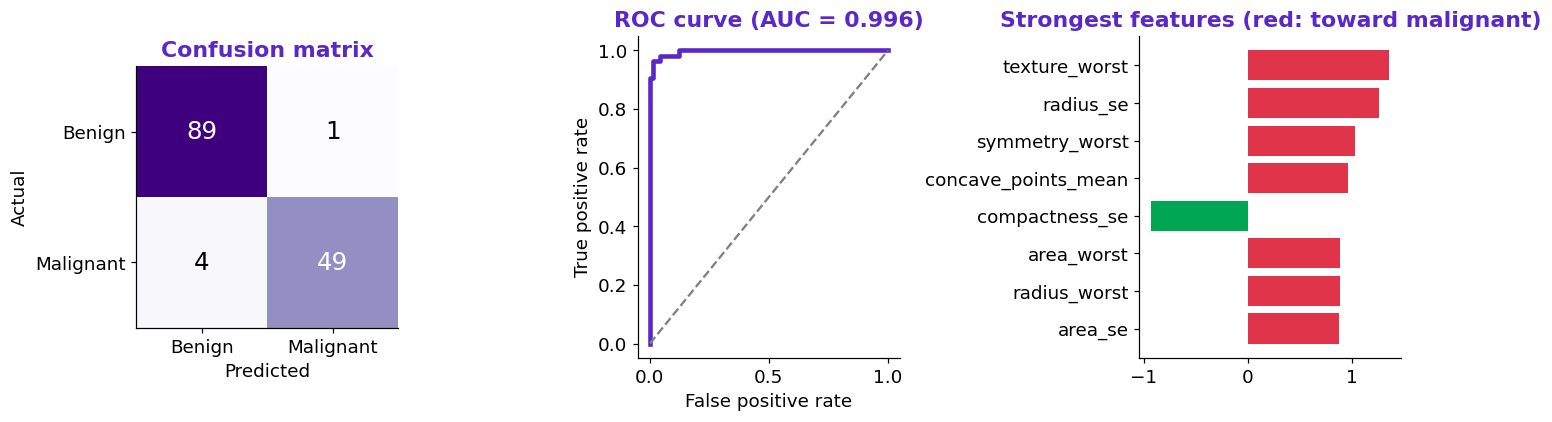

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 4))

ax[0].imshow(cm, cmap="Purples")
for (i, j), v in np.ndenumerate(cm):
    ax[0].text(j, i, v, ha="center", va="center", fontsize=16, color="white" if v > cm.max() / 2 else "black")
ax[0].set(title="Confusion matrix", xticks=[0, 1], yticks=[0, 1], xticklabels=["Benign", "Malignant"],
          yticklabels=["Benign", "Malignant"], xlabel="Predicted", ylabel="Actual")

fpr, tpr, _ = roc_curve(y_test, y_prob)
ax[1].plot(fpr, tpr, color=PURPLE, lw=3)
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set(title=f"ROC curve (AUC = {auc:.3f})", xlabel="False positive rate", ylabel="True positive rate")

weights = pd.Series(model.named_steps["logisticregression"].coef_[0], index=feature_names)
top = weights.reindex(weights.abs().sort_values().index).tail(8)
ax[2].barh(top.index, top.values, color=[RED if v > 0 else GREEN for v in top.values])
ax[2].set(title="Strongest features (red: toward malignant)")
fig.tight_layout()
plt.show()

In [9]:
# SAVE THE RESULTS. The figure and the metrics are written to a "results" folder.
# These exact files are what the course slides show.
import json

results_dir = Path("results")
results_dir.mkdir(exist_ok=True)
fig.savefig(results_dir / "02_logistic_regression.png", dpi=170, bbox_inches="tight", facecolor="white")

results = {
    "model": "Logistic Regression",
    "dataset": "Breast Cancer Wisconsin (UCI)",
    "n_samples": int(len(df)),
    "metrics": {"Accuracy": round(accuracy, 4), "Precision": round(precision, 4), "Recall": round(recall, 4), "F1": round(f1, 4), "ROC AUC": round(auc, 4)},
}
(results_dir / "02_logistic_regression.json").write_text(json.dumps(results, indent=2), encoding="utf-8")
print(json.dumps(results, indent=2))

{
  "model": "Logistic Regression",
  "dataset": "Breast Cancer Wisconsin (UCI)",
  "n_samples": 569,
  "metrics": {
    "Accuracy": 0.965,
    "Precision": 0.98,
    "Recall": 0.9245,
    "F1": 0.9515,
    "ROC AUC": 0.9962
  }
}


## What to remember
- Logistic regression gives a probability, so the decision threshold can be moved.
- **Try it yourself:** predict malignant when `y_prob > 0.3`. What happens to precision and recall?